# Churn de suscripciones: Analisis exploratorio

Explora exclusivamente entrenamiento y genera cifras, comentarios y una figura. Test queda reservado.

**Estado:** ejecutado el 6 de octubre de 2026; resultados exploratorios revisados en README y docs/ejecuciones.md. Consulta ../docs/metodologia.md.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("subscription_churn")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from subscription_churn.alertas import configurar_notebook, mostrar_alertas
configurar_notebook()


# EDA de entrenamiento

Registros: **352,665**. Churn positivo: **56.71%**. La clase negativa es minoritaria.

Se explora solo train: validación selecciona el modelo y test queda reservado. No se infiere causalidad ni representatividad de estas cifras.

## Nulos por columna

```text
                   nulos
CustomerID             0
Age                    0
Gender                 0
Tenure                 0
Usage Frequency        0
Support Calls          0
Payment Delay          0
Subscription Type      0
Contract Length        0
Total Spend            0
Last Interaction       0
Churn                  0
```

## Atributos excluidos

CustomerID


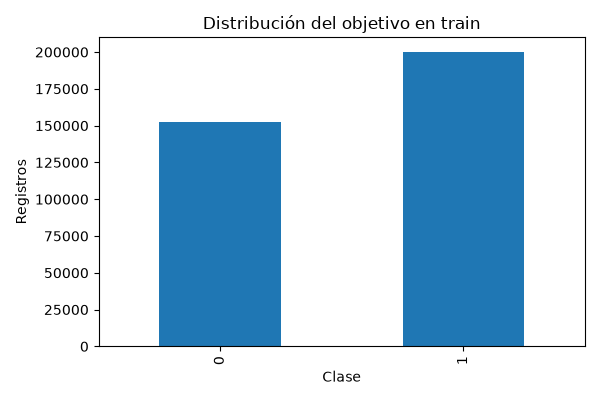

In [2]:
from subscription_churn.flujo import explorar
from IPython.display import Image
display(Markdown(explorar(PROJECT_ROOT)))
display(Image(filename=str(PROJECT_ROOT / "reports/eda/distribucion_target.png")))


## Alertas de la ejecucion

Avisos agrupados con descripcion generica, acciones sugeridas y detalle original. Los errores de celda no se ocultan.

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/02_analisis_exploratorio.json")
from subscription_churn.informe import generar_informe
generar_informe(PROJECT_ROOT)


WindowsPath('D:/portafolio/Analisis/churn/SubscriptionChurn/reports/informe_final/informe_final.md')